In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
class Charge:
    def __init__(self, q: float, r: np.ndarray) -> None:
        self.q = q
        self.rp = r

    def E(self, X , Y, eps=1e-4):
        dx = X - self.rp[0]
        dy = Y - self.rp[1]
        d3 = (dx**2 + dy**2 + eps**2)**1.5
        return self.q*np.array([ dx/d3, dy/d3 ])

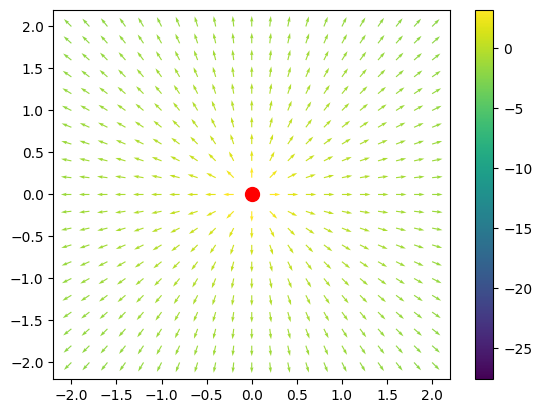

In [4]:
q = Charge(1, np.array([0,0]))

x = np.linspace(-2,2, 21)
X, Y = np.meshgrid( x, x )

Ex, Ey = q.E(X,Y)
E = np.hypot(Ex,Ey) + 1e-12
plt.quiver(X,Y, Ex/E, Ey/E, np.log(E), cmap="viridis")
plt.plot(*q.rp, "or", ms=10)
plt.colorbar()

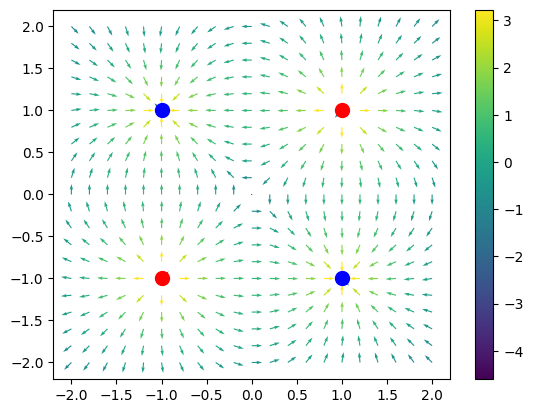

In [5]:
Q = [
    Charge(-1, np.array([1,-1])),
    Charge(1, np.array([1,1])),
    Charge(-1, np.array([-1,1])),
    Charge(1, np.array([-1,-1])),
]

x = np.linspace(-2,2, 21)
X, Y = np.meshgrid( x, x )

Ex, Ey = sum( qi.E(X,Y) for qi in Q )
E = np.hypot(Ex,Ey) + 1e-2

plt.quiver(X,Y, Ex/E, Ey/E, np.log(E), cmap="viridis")

for qi in Q:
    plt.plot( *qi.rp, "o", color = "r" if qi.q > 0 else "b", ms=10)
plt.colorbar()

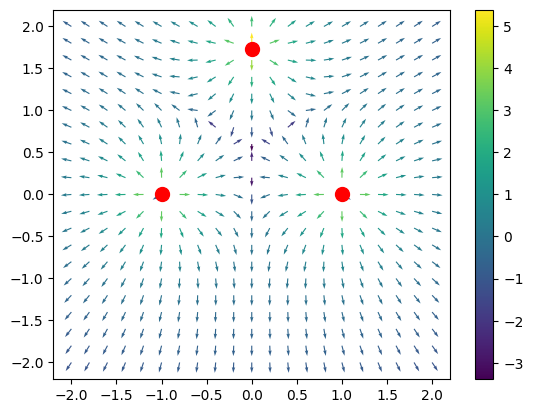

In [6]:
Q = [
    Charge(1, np.array([-1,0])),
    Charge(1, np.array([1,0])),
    Charge(1, np.array([0.0, np.sqrt(3)])),
]

x = np.linspace(-2,2, 21)
X, Y = np.meshgrid( x, x )

Ex, Ey = sum( qi.E(X,Y) for qi in Q )
E = np.hypot(Ex,Ey) + 1e-2

plt.quiver(X,Y, Ex/E, Ey/E, np.log(E), cmap="viridis")

for qi in Q:
    plt.plot( *qi.rp, "o", color = "r" if qi.q > 0 else "b", ms=10)
plt.colorbar()

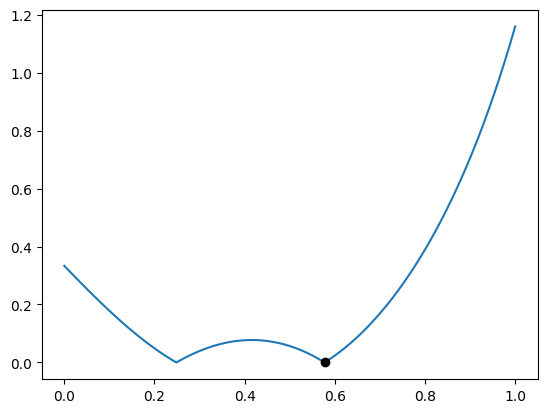

In [7]:
y = np.linspace(0,1,500)
Ex, Ey = sum( qi.E(0,y) for qi in Q)

rm = 1/3*sum( qi.rp for qi in Q )
Em = sum( qi.E(*rm) for qi in Q)

plt.plot(y, np.hypot(Ex,Ey) )
plt.plot( rm[1], 0, "ok")
plt.show()